## 1. Carregamento e Preparação Espacial dos Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from mpl_toolkits.mplot3d import Axes3D
import time
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)

from pathlib import Path
# Detecta dinamicamente a pasta de saída e o local da matriz analítica
output_dir = Path('dados_output') if Path('dados_output').exists() or not Path('/content').exists() else Path('/content/dados_output')
output_dir.mkdir(parents=True, exist_ok=True)
output_path = str(output_dir)

# Busca a matriz analítica nos caminhos comuns
candidatos_matriz = [
    output_dir / 'matriz_analitica_kdd_final.parquet',
    Path('matriz_analitica_kdd_final.parquet'),
    Path('/content/matriz_analitica_kdd_final.parquet'),
    Path('/content/dados_output/matriz_analitica_kdd_final.parquet')
]
caminho_matriz_encontrado = next((p for p in candidatos_matriz if p.exists()), output_dir / 'matriz_analitica_kdd_final.parquet')


# 1. Carregamento do Artefato Consolidado Definitivo (Notebook 04)
caminho_matriz = output_path + '/matriz_analitica_kdd_final.parquet'

try:
    df_kdd = pd.read_parquet(caminho_matriz_encontrado)
    print(f"[SUCESSO] Base Analítica carregada. Total de inscrições agregadas: {len(df_kdd):,}")
except Exception as e:
    print(f"[ERRO CRÍTICO] Arquivo não encontrado. Erro: {e}")

# 2. Definição das Variáveis Contínuas (O mesmo espaço vetorial validado na Rota B)
features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

print("\n[PREPARANDO O ESPAÇO VETORIAL - 100% DAS INSCRIÇÕES]")
df_rota_a = df_kdd.copy()

# 3.1 Instanciação e treinamento do padronizador sobre a matriz global
scaler_a = StandardScaler()
scaled_features_a = scaler_a.fit_transform(df_rota_a[features_ml])

# 3.2 Reconstrução do subespaço de variáveis padronizadas
df_rota_a_scaled = pd.DataFrame(scaled_features_a, columns=features_ml, index=df_rota_a.index)

# 3.3 Preservação das colunas de identificação e metadados contextuais
cols_identificacao = [col for col in df_rota_a.columns if col not in features_ml]
df_ml_a = pd.concat([df_rota_a[cols_identificacao], df_rota_a_scaled], axis=1)

print("-" * 70)
print(f"-> Rota A instanciada: {len(df_ml_a):,} registros prontos para modelagem.")
print(f"-> Espaço vetorial de {len(features_ml)} dimensões padronizado (Z-Score).")
print(f"-> Metadados contextuais preservados: {len(cols_identificacao)} atributos.")


[SUCESSO] Base Analítica carregada. Total de inscrições agregadas: 191,412

[PREPARANDO O ESPAÇO VETORIAL - 100% DAS INSCRIÇÕES]
----------------------------------------------------------------------
-> Rota A instanciada: 191,412 registros prontos para modelagem.
-> Espaço vetorial de 7 dimensões padronizado (Z-Score).
-> Metadados contextuais preservados: 30 atributos.


## 2. Otimização do Hiperparâmetro $K$

Treinando modelo espacial para K=2...
   -> Concluído K=2 | Inércia: 972,269 | Silhueta (Amostra): 0.3379
Treinando modelo espacial para K=3...
   -> Concluído K=3 | Inércia: 701,969 | Silhueta (Amostra): 0.4089
Treinando modelo espacial para K=4...
   -> Concluído K=4 | Inércia: 517,382 | Silhueta (Amostra): 0.4351
Treinando modelo espacial para K=5...
   -> Concluído K=5 | Inércia: 456,127 | Silhueta (Amostra): 0.3581
Treinando modelo espacial para K=6...
   -> Concluído K=6 | Inércia: 405,554 | Silhueta (Amostra): 0.3092
Treinando modelo espacial para K=7...
   -> Concluído K=7 | Inércia: 364,015 | Silhueta (Amostra): 0.3207
Treinando modelo espacial para K=8...
   -> Concluído K=8 | Inércia: 335,045 | Silhueta (Amostra): 0.3129

VARREDURA CONCLUÍDA EM 3.5 MINUTOS. GERANDO GRÁFICOS (ROTA A)...
----------------------------------------------------------------------


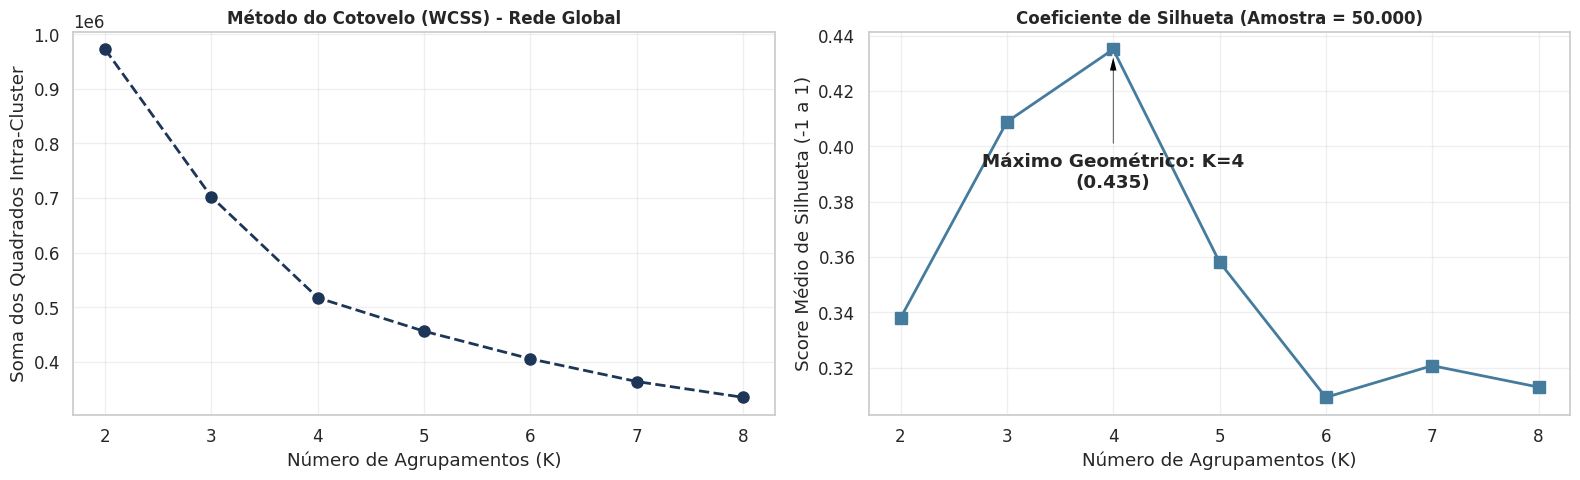

In [ ]:
inicio_tempo = time.time()

# Isolando o subespaço vetorial padronizado da Rota A
X_a = df_ml_a[features_ml]

# Estruturas para armazenamento das métricas de validação
inercia_a = []
silhueta_a = []
intervalo_k = range(2, 9)

labels_a_dict = {}

# Iteração de treinamento e avaliação espacial
for k in intervalo_k:
    print(f"Treinando modelo espacial para K={k}...")

    # Instanciação do modelo com semente controlada para reprodutibilidade estrita
    kmeans_a = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_a = kmeans_a.fit_predict(X_a)

    # Armazenamento dos rótulos para eventual reutilização
    labels_a_dict[k] = labels_a

    # 1. Armazenamento da Inércia (Calculada sobre a população integral)
    inercia_a.append(kmeans_a.inertia_)

    # 2. Armazenamento da Silhueta (Calculada sobre a amostra de mitigação de hardware)
    score_sil_a = silhouette_score(X_a, labels_a, sample_size=50000, random_state=42)
    silhueta_a.append(score_sil_a)

    print(f"   -> Concluído K={k} | Inércia: {kmeans_a.inertia_:,.0f} | Silhueta (Amostra): {score_sil_a:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"VARREDURA CONCLUÍDA EM {tempo_total:.1f} MINUTOS. GERANDO GRÁFICOS (ROTA A)...")
print("-" * 70)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Método do Cotovelo (Inércia)
axes[0].plot(intervalo_k, inercia_a, marker='o', linestyle='--', color='#1d3557', linewidth=2, markersize=8)
axes[0].set_title('Método do Cotovelo (WCSS) - Rede Global', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Número de Agrupamentos (K)')
axes[0].set_ylabel('Soma dos Quadrados Intra-Cluster')
axes[0].set_xticks(intervalo_k)
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Coeficiente de Silhueta
axes[1].plot(intervalo_k, silhueta_a, marker='s', linestyle='-', color='#457b9d', linewidth=2, markersize=8)
axes[1].set_title('Coeficiente de Silhueta (Amostra = 50.000)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Número de Agrupamentos (K)')
axes[1].set_ylabel('Score Médio de Silhueta (-1 a 1)')
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.3)

# Anotação do valor ótimo de Silhueta para destaque visual e acadêmico
k_max_sil_a = intervalo_k[np.argmax(silhueta_a)]
max_sil_val_a = max(silhueta_a)
axes[1].annotate(f'Máximo Geométrico: K={k_max_sil_a}\n({max_sil_val_a:.3f})',
                 xy=(k_max_sil_a, max_sil_val_a),
                 xytext=(k_max_sil_a, max_sil_val_a - 0.05),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
                 horizontalalignment='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Redução de Dimensionalidade: Análise de Componentes Principais (PCA) na Rede Global

[ANÁLISE DE VARIÂNCIA DOS COMPONENTES - REDE GLOBAL]
-> PC1: Explica 32.84% da variância | Cumulativo: 32.84%
-> PC2: Explica 21.04% da variância | Cumulativo: 53.88%
-> PC3: Explica 16.28% da variância | Cumulativo: 70.16%
-> PC4: Explica 14.21% da variância | Cumulativo: 84.37%
-> PC5: Explica 11.94% da variância | Cumulativo: 96.31%
-> PC6: Explica 3.00% da variância | Cumulativo: 99.30%
-> PC7: Explica 0.70% da variância | Cumulativo: 100.00%


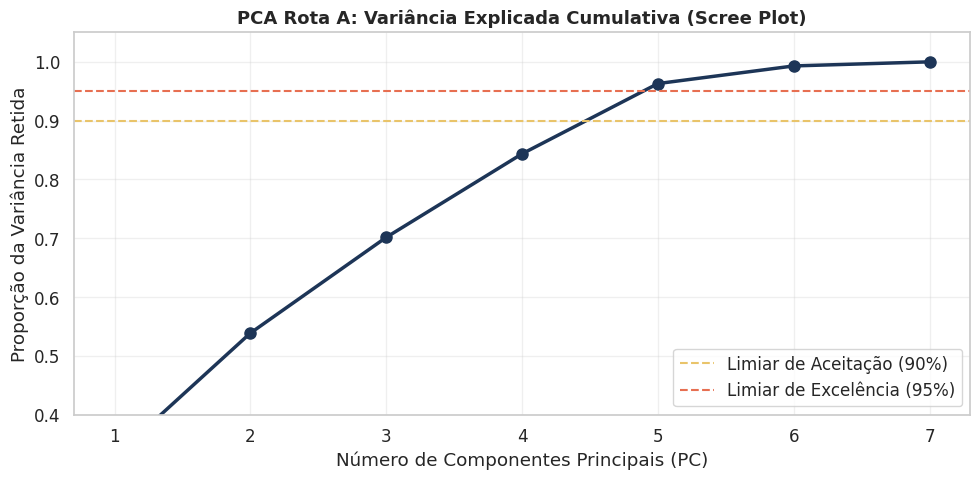


APLICANDO TRANSFORMAÇÃO ORTOGONAL (LIMIAR DE 95%) - ROTA A
----------------------------------------------------------------------
[RESULTADO DA TRANSFORMAÇÃO ESPACIAL]
-> Redução dimensional: De 7 dimensões originais para 5 Componentes Principais (PCs).
-> O subespaço vetorial comprimido (X_pca_a) preserva 96.31% da macroestrutura comportamental.
-> Matriz de 191.412 inscrições pronta para o particionamento final via K-Means (K=4).


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# 1. Instanciação do PCA para mapeamento de 100% da variância original
pca_full_a = PCA(random_state=42)
pca_full_a.fit(X_a) # X_a corresponde à matriz padronizada contendo 191.412 registros

# Cálculo da variância explicada individual e cumulativa
variancia_explicada_a = pca_full_a.explained_variance_ratio_
variancia_cumulativa_a = np.cumsum(variancia_explicada_a)

print("[ANÁLISE DE VARIÂNCIA DOS COMPONENTES - REDE GLOBAL]")
for i, (var, cum_var) in enumerate(zip(variancia_explicada_a, variancia_cumulativa_a), start=1):
    print(f"-> PC{i}: Explica {var*100:.2f}% da variância | Cumulativo: {cum_var*100:.2f}%")

# 2. PLOTAGEM DO GRÁFICO DE VARIÂNCIA CUMULATIVA (SCREE PLOT)
plt.figure(figsize=(10, 5))

# Utilização de paleta sóbria (tons de azul/escuro)
plt.plot(range(1, len(variancia_explicada_a) + 1), variancia_cumulativa_a, marker='o',
         linestyle='-', color='#1d3557', linewidth=2.5, markersize=8)

# Linhas de corte metodológico
plt.axhline(y=0.90, color='#e9c46a', linestyle='--', label='Limiar de Aceitação (90%)')
plt.axhline(y=0.95, color='#e76f51', linestyle='--', label='Limiar de Excelência (95%)')

plt.title('PCA Rota A: Variância Explicada Cumulativa (Scree Plot)', fontweight='bold', fontsize=13)
plt.xlabel('Número de Componentes Principais (PC)')
plt.ylabel('Proporção da Variância Retida')
plt.xticks(range(1, len(variancia_explicada_a) + 1))
plt.ylim(0.4, 1.05)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. APLICANDO A REDUÇÃO FINAL (RETENÇÃO DE 95%)
print("\n" + "=" * 70)
print("APLICANDO TRANSFORMAÇÃO ORTOGONAL (LIMIAR DE 95%) - ROTA A")
print("-" * 70)

# Instanciação dinâmica com retenção de 95% da variância explicada
pca_opt_a = PCA(n_components=0.95, random_state=42)
X_pca_a = pca_opt_a.fit_transform(X_a)

n_comp_opt_a = pca_opt_a.n_components_
var_final_a = np.sum(pca_opt_a.explained_variance_ratio_) * 100

print(f"[RESULTADO DA TRANSFORMAÇÃO ESPACIAL]")
print(f"-> Redução dimensional: De {X_a.shape[1]} dimensões originais para {n_comp_opt_a} Componentes Principais (PCs).")
print(f"-> O subespaço vetorial comprimido (X_pca_a) preserva {var_final_a:.2f}% da macroestrutura comportamental.")
print("-> Matriz de 191.412 inscrições pronta para o particionamento final via K-Means (K=4).")

### 3.1. Revalidação Geométrica: O Hiperparâmetro $K$ no Subespaço Ortogonal

Revalidando as métricas geométricas no subespaço ortogonal (PCA)...
Calculando Inércia para a população integral e Silhueta para amostra de 50.000.
----------------------------------------------------------------------
   -> Concluído K=2 (PCA) | Inércia: 922,801 | Silhueta (Amostra 50k): 0.3518
   -> Concluído K=3 (PCA) | Inércia: 653,121 | Silhueta (Amostra 50k): 0.4260
   -> Concluído K=4 (PCA) | Inércia: 468,534 | Silhueta (Amostra 50k): 0.4533
   -> Concluído K=5 (PCA) | Inércia: 407,755 | Silhueta (Amostra 50k): 0.3793
   -> Concluído K=6 (PCA) | Inércia: 357,073 | Silhueta (Amostra 50k): 0.3308
   -> Concluído K=7 (PCA) | Inércia: 320,712 | Silhueta (Amostra 50k): 0.3701
   -> Concluído K=8 (PCA) | Inércia: 287,904 | Silhueta (Amostra 50k): 0.3358

REVALIDAÇÃO CONCLUÍDA EM 3.4 MINUTOS. GERANDO GRÁFICOS...
----------------------------------------------------------------------


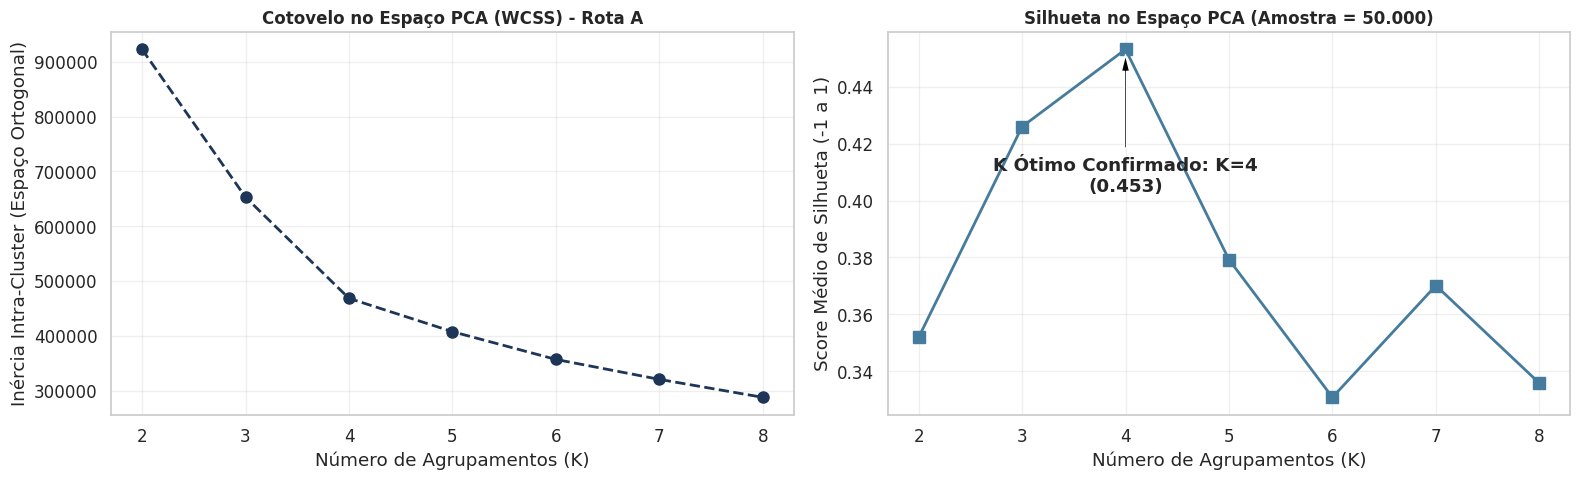

In [ ]:
# 3.1. RECALCULANDO O K ÓTIMO (ELBOW E SILHOUETTE) NO ESPAÇO PCA (ROTA A)

print("Revalidando as métricas geométricas no subespaço ortogonal (PCA)...")
print("Calculando Inércia para a população integral e Silhueta para amostra de 50.000.")
print("-" * 70)

inicio_tempo = time.time()

inercia_pca_a = []
silhueta_pca_a = []
intervalo_k = range(2, 9)

labels_pca_a_dict = {}

# Iteração de treinamento focada EXCLUSIVAMENTE na matriz X_pca_a
for k in intervalo_k:
    # Instanciação com semente controlada para reprodutibilidade
    kmeans_pca = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels_pca_a = kmeans_pca.fit_predict(X_pca_a)

    # Armazenamento dos rótulos para reutilização na triangulação
    labels_pca_a_dict[k] = labels_pca_a

    # 1. Inércia (WCSS) populacional
    inercia_pca_a.append(kmeans_pca.inertia_)

    # 2. Silhueta Amostral (Mitigação de estouro de memória)
    score_sil_pca_a = silhouette_score(X_pca_a, labels_pca_a, sample_size=50000, random_state=42)
    silhueta_pca_a.append(score_sil_pca_a)

    print(f"   -> Concluído K={k} (PCA) | Inércia: {kmeans_pca.inertia_:,.0f} | Silhueta (Amostra 50k): {score_sil_pca_a:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"REVALIDAÇÃO CONCLUÍDA EM {tempo_total:.1f} MINUTOS. GERANDO GRÁFICOS...")
print("-" * 70)

# PLOTAGEM DUPLA: VALIDAÇÃO NO ESPAÇO PCA (ROTA A)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Método do Cotovelo (Inércia no PCA)
axes[0].plot(intervalo_k, inercia_pca_a, marker='o', linestyle='--', color='#1d3557', linewidth=2, markersize=8)
axes[0].set_title('Cotovelo no Espaço PCA (WCSS) - Rota A', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Número de Agrupamentos (K)')
axes[0].set_ylabel('Inércia Intra-Cluster (Espaço Ortogonal)')
axes[0].set_xticks(intervalo_k)
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Coeficiente de Silhueta (PCA - Amostra)
axes[1].plot(intervalo_k, silhueta_pca_a, marker='s', linestyle='-', color='#457b9d', linewidth=2, markersize=8)
axes[1].set_title('Silhueta no Espaço PCA (Amostra = 50.000)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Número de Agrupamentos (K)')
axes[1].set_ylabel('Score Médio de Silhueta (-1 a 1)')
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.3)

# Anotação visual do valor ótimo de Silhueta
k_max_sil_pca_a = intervalo_k[np.argmax(silhueta_pca_a)]
max_sil_val_pca_a = max(silhueta_pca_a)
axes[1].annotate(f'K Ótimo Confirmado: K={k_max_sil_pca_a}\n({max_sil_val_pca_a:.3f})',
                 xy=(k_max_sil_pca_a, max_sil_val_pca_a),
                 xytext=(k_max_sil_pca_a, max_sil_val_pca_a - 0.05),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
                 horizontalalignment='center', fontweight='bold')

plt.tight_layout()
plt.show()


### Revalidação geométrica do número ótimo de clusters no espaço PCA — Rota A

Carregando base analítica consolidada da Rota A...
Rota A preparada com 191,412 registros.
Aplicando padronização Z-score...
Aplicando PCA com retenção mínima de 95% da variância...
Dimensionalidade reduzida: 7 -> 5 componentes.
Variância retida: 96.31%
----------------------------------------------------------------------
Revalidando as métricas geométricas no subespaço PCA da Rota A...
Calculando WCSS para a população integral e Silhueta para amostra de 50.000.
[ALERTA] Esta execução pode levar alguns minutos devido ao cálculo da Silhueta.
----------------------------------------------------------------------
Treinando modelo no espaço PCA para K=2...
   -> Concluído K=2 | Inércia: 922,801 | Silhueta (Amostra 50k): 0.3518
Treinando modelo no espaço PCA para K=3...
   -> Concluído K=3 | Inércia: 653,121 | Silhueta (Amostra 50k): 0.4260
Treinando modelo no espaço PCA para K=4...
   -> Concluído K=4 | Inércia: 468,534 | Silhueta (Amostra 50k): 0.4533
Treinando modelo no espaço PCA para 

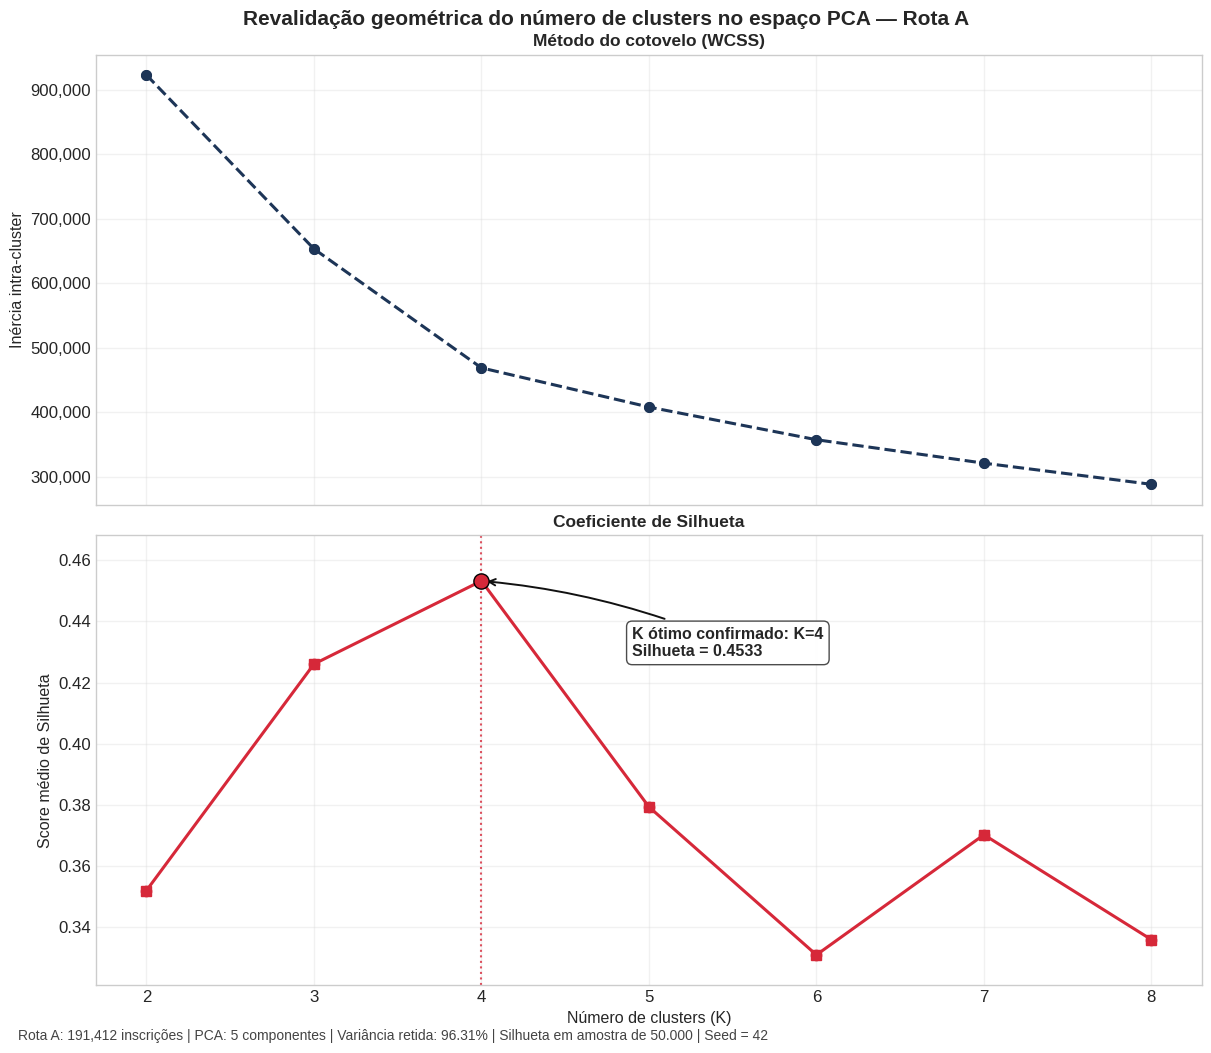


Arquivos gerados com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_a_revalidacao_pca_vertical_300dpi.png
-> No espaço PCA, a solução com maior Silhueta permanece em K=4.


In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")

# 1. CARREGAMENTO E PREPARAÇÃO DA ROTA A
print("Carregando base analítica consolidada da Rota A...")
caminho_parquet = output_path + '/matriz_analitica_kdd_final.parquet'
df_rota_a = pd.read_parquet(caminho_parquet)

features_ml_a = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

faltantes = [c for c in features_ml_a if c not in df_rota_a.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base da Rota A: {faltantes}")

print(f"Rota A preparada com {len(df_rota_a):,} registros.")

# 2. PADRONIZAÇÃO E PCA
print("Aplicando padronização Z-score...")
Xa = df_rota_a[features_ml_a].copy()
Xa_scaled = StandardScaler().fit_transform(Xa)

print("Aplicando PCA com retenção mínima de 95% da variância...")
pca_a = PCA(n_components=0.95, random_state=42)
X_pca_a = pca_a.fit_transform(Xa_scaled)

n_comp_a = pca_a.n_components_
var_retida_a = pca_a.explained_variance_ratio_.sum() * 100

print(f"Dimensionalidade reduzida: {Xa.shape[1]} -> {n_comp_a} componentes.")
print(f"Variância retida: {var_retida_a:.2f}%")

# 3. REVALIDAÇÃO DE K NO ESPAÇO PCA
print("-" * 70)
print("Revalidando as métricas geométricas no subespaço PCA da Rota A...")
print("Calculando WCSS para a população integral e Silhueta para amostra de 50.000.")
print("[ALERTA] Esta execução pode levar alguns minutos devido ao cálculo da Silhueta.")
print("-" * 70)

inicio_tempo = time.time()

intervalo_k = list(range(2, 9))
inercia_pca_a = []
silhueta_pca_a = []
labels_pca_a_dict = {}

for k in intervalo_k:
    print(f"Treinando modelo no espaço PCA para K={k}...")

    kmeans_pca = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels_pca_a = kmeans_pca.fit_predict(X_pca_a)
    labels_pca_a_dict[k] = labels_pca_a

    inertia_val = kmeans_pca.inertia_
    sil_val = silhouette_score(
        X_pca_a,
        labels_pca_a,
        sample_size=50000,
        random_state=42
    )

    inercia_pca_a.append(inertia_val)
    silhueta_pca_a.append(sil_val)

    print(f"   -> Concluído K={k} | Inércia: {inertia_val:,.0f} | Silhueta (Amostra 50k): {sil_val:.4f}")

tempo_total = (time.time() - inicio_tempo) / 60
print("\n" + "=" * 70)
print(f"REVALIDAÇÃO CONCLUÍDA EM {tempo_total:.1f} MINUTOS.")
print("-" * 70)

k_max_sil_pca_a = intervalo_k[int(np.argmax(silhueta_pca_a))]
max_sil_val_pca_a = max(silhueta_pca_a)

# 4. VISUALIZAÇÃO APRIMORADA
plt.style.use('seaborn-v0_8-whitegrid')

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True
)

fig.suptitle(
    'Revalidação geométrica do número de clusters no espaço PCA — Rota A',
    fontsize=15,
    fontweight='bold',
    y=1.02
)

cores = {
    "inercia": "#1d3557",
    "silhueta": "#d62839",
    "destaque": "#111111",
    "grade": "#d9d9d9"
}

# Gráfico 1: Cotovelo
axes[0].plot(
    intervalo_k, inercia_pca_a,
    marker='o', linestyle='--',
    color=cores["inercia"],
    linewidth=2.2, markersize=7
)
axes[0].scatter(intervalo_k, inercia_pca_a, color=cores["inercia"], s=45, zorder=3)
axes[0].set_title('Método do cotovelo (WCSS)', fontsize=12.5, fontweight='bold')
axes[0].set_ylabel('Inércia intra-cluster', fontsize=11.5)
axes[0].grid(True, alpha=0.35, color=cores["grade"])
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'))

# Gráfico 2: Silhueta
axes[1].plot(
    intervalo_k, silhueta_pca_a,
    marker='s', linestyle='-',
    color=cores["silhueta"],
    linewidth=2.2, markersize=7
)
axes[1].scatter(intervalo_k, silhueta_pca_a, color=cores["silhueta"], s=55, zorder=3)
axes[1].scatter(
    [k_max_sil_pca_a], [max_sil_val_pca_a],
    color=cores["silhueta"], s=120,
    edgecolor='black', linewidth=1.0, zorder=5
)
axes[1].axvline(
    x=k_max_sil_pca_a,
    color=cores["silhueta"],
    linestyle=':',
    linewidth=1.5,
    alpha=0.8
)

axes[1].set_title('Coeficiente de Silhueta', fontsize=12.5, fontweight='bold')
axes[1].set_xlabel('Número de clusters (K)', fontsize=11.5)
axes[1].set_ylabel('Score médio de Silhueta', fontsize=11.5)
axes[1].set_xticks(intervalo_k)
axes[1].grid(True, alpha=0.35, color=cores["grade"])

margem_inf = max(0, min(silhueta_pca_a) - 0.01)
margem_sup = max(silhueta_pca_a) + 0.015
axes[1].set_ylim(margem_inf, margem_sup)

texto_anotacao = (
    f"K ótimo confirmado: K={k_max_sil_pca_a}\n"
    f"Silhueta = {max_sil_val_pca_a:.4f}"
)

# Ajuste de posição da anotação
if k_max_sil_pca_a <= 5:
    x_text = k_max_sil_pca_a + 0.9
else:
    x_text = k_max_sil_pca_a - 1.8

y_text = max_sil_val_pca_a - 0.015

axes[1].annotate(
    texto_anotacao,
    xy=(k_max_sil_pca_a, max_sil_val_pca_a),
    xytext=(x_text, y_text),
    textcoords='data',
    fontsize=11.5,
    fontweight='bold',
    ha='left',
    va='top',
    bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#444444', alpha=0.96),
    arrowprops=dict(
        arrowstyle='->',
        color=cores["destaque"],
        lw=1.4,
        shrinkA=4,
        shrinkB=4,
        connectionstyle='arc3,rad=0.08'
    )
)

fig.text(
    0.01, -0.01,
    f"Rota A: {len(df_rota_a):,} inscrições | PCA: {n_comp_a} componentes | Variância retida: {var_retida_a:.2f}% | Silhueta em amostra de 50.000 | Seed = 42",
    fontsize=10,
    color="#444444"
)

# 5. EXPORTAÇÃO EM PNG 300 DPI
output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)

arquivo_png = os.path.join(output_dir, "rota_a_revalidacao_pca_vertical_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivos gerados com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")

print(f"-> No espaço PCA, a solução com maior Silhueta permanece em K={k_max_sil_pca_a}.")

### 3.2. Triangulação Matemática: Índices de Calinski-Harabasz e Davies-Bouldin

In [ ]:
# 3.5. TRIANGULAÇÃO MATEMÁTICA: CALINSKI-HARABASZ E DAVIES-BOULDIN (ROTA A)

resultados_triangulacao_a = []
intervalo_teste = range(2, 9)  # Alinhado rigorosamente à execução do Passo 3.3

for k in intervalo_teste:
    labels_temp_a = labels_pca_a_dict[k]

    # Cálculo dos estimadores complementares (O(N), executáveis sobre a base total)
    ch_score_a = calinski_harabasz_score(X_pca_a, labels_temp_a)
    db_score_a = davies_bouldin_score(X_pca_a, labels_temp_a)

    # Recuperação do Coeficiente de Silhueta calculado previamente (Passo 3.3)
    sil_score_a = silhueta_pca_a[k-2]

    # Armazenamento estruturado dos indicadores
    resultados_triangulacao_a.append({
        'K (Número de Clusters)': k,
        'Silhueta Amostral (Maximização)': round(sil_score_a, 4),
        'Calinski-Harabasz (Maximização)': round(ch_score_a, 1),
        'Davies-Bouldin (Minimização)': round(db_score_a, 4)
    })

# Consolidação da matriz de auditoria analítica
df_provas_a = pd.DataFrame(resultados_triangulacao_a).set_index('K (Número de Clusters)')
print("[QUADRO DE VALIDAÇÃO ESTATÍSTICA CRUZADA - ROTA A]")
display(df_provas_a)

[QUADRO DE VALIDAÇÃO ESTATÍSTICA CRUZADA - ROTA A]


,Silhueta Amostral (Maximização),Calinski-Harabasz (Maximização),Davies-Bouldin (Minimização)
K (Número de Clusters),,,
2,0.3518,76250.3,1.2567
3,0.4260,93384.3,0.9776
4,0.4533,111918.7,0.7790
5,0.3793,103583.3,0.9205
6,0.3308,100063.5,1.0401
7,0.3701,96454.7,0.9198
8,0.3358,95212.2,1.0702


## 4. Modelagem Macropolítica: Particionamento Definitivo no Subespaço Ortogonal

Instanciando K-Means Definitivo (K=4) sobre o subespaço ortogonal...
Processando população integral (191,412 inscrições)...
----------------------------------------------------------------------
[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS NA REDE GLOBAL]
-> Cluster 0: 86,775 inscrições (45.3%)
-> Cluster 1: 73,175 inscrições (38.2%)
-> Cluster 2: 27,977 inscrições (14.6%)
-> Cluster 3: 3,485 inscrições (1.8%)

GERANDO PROJEÇÃO GEOMÉTRICA 3D DA ROTA A (AMOSTRAGEM DE DISPERSÃO)
----------------------------------------------------------------------


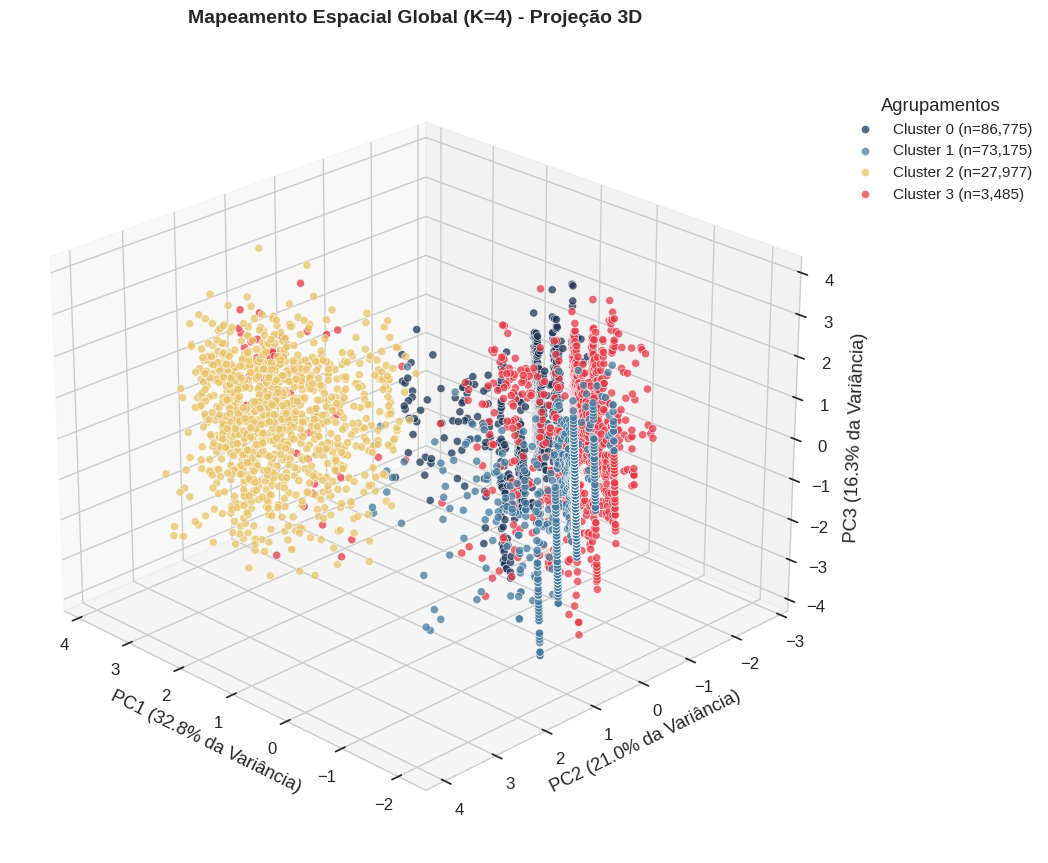

In [ ]:
# 4. APLICAÇÃO DO ALGORITMO K-MEANS DEFINITIVO (K=4) - ROTA A

print("Instanciando K-Means Definitivo (K=4) sobre o subespaço ortogonal...")
print(f"Processando população integral ({len(df_rota_a):,} inscrições)...")
print("-" * 70)

# 1. Treinamento e Predição do Modelo Espacial
kmeans_pca_a = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
clusters_k4_a = kmeans_pca_a.fit_predict(X_pca_a)

# 2. Reintegração dos Rótulos (Labels) à Base Analítica Original
df_rota_a['Cluster_K4'] = clusters_k4_a

for i in range(n_comp_opt_a):
    df_rota_a[f'PC{i+1}'] = X_pca_a[:, i]

# 3. Dimensionamento da Demografia Macropolítica
distribuicao_a = df_rota_a['Cluster_K4'].value_counts().sort_index()
print("[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS NA REDE GLOBAL]")
for cluster, count in distribuicao_a.items():
    print(f"-> Cluster {cluster}: {count:,} inscrições ({(count/len(df_rota_a))*100:.1f}%)")

# 4. VISUALIZAÇÃO ESPACIAL 3D (RENDERIZAÇÃO GEOMÉTRICA)
print("\n" + "=" * 70)
print("GERANDO PROJEÇÃO GEOMÉTRICA 3D DA ROTA A (AMOSTRAGEM DE DISPERSÃO)")
print("-" * 70)

fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')

cores_a = {0: '#1d3557', 1: '#457b9d', 2: '#e9c46a', 3: '#e63946'}
nomes_temporarios_a = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 3: 'Cluster 3'}
tamanhos = df_rota_a['Cluster_K4'].value_counts()

ordem_plotagem = tamanhos.sort_values(ascending=False).index.tolist()

for c in ordem_plotagem:
    idx = df_rota_a['Cluster_K4'] == c
    df_subset = df_rota_a.loc[idx]
    qtd_pontos_real = tamanhos[c]

    sample_size = min(qtd_pontos_real, 1000)
    if qtd_pontos_real > sample_size:
        df_subset = df_subset.sample(n=sample_size, random_state=42)

    # Renderização da nuvem de pontos
    ax.scatter(df_subset['PC1'],
               df_subset['PC2'],
               df_subset['PC3'],
               c=cores_a[c],
               label=f'{nomes_temporarios_a[c]} (n={qtd_pontos_real:,})',
               s=35,
               alpha=0.75,
               edgecolors='white',
               linewidth=0.5)

ax.set_title('Mapeamento Espacial Global (K=4) - Projeção 3D', fontweight='bold', fontsize=14, pad=15)

var_pc1 = pca_opt_a.explained_variance_ratio_[0] * 100
var_pc2 = pca_opt_a.explained_variance_ratio_[1] * 100
var_pc3 = pca_opt_a.explained_variance_ratio_[2] * 100

ax.set_xlabel(f'PC1 ({var_pc1:.1f}% da Variância)')
ax.set_ylabel(f'PC2 ({var_pc2:.1f}% da Variância)')
ax.set_zlabel(f'PC3 ({var_pc3:.1f}% da Variância)')

# Posicionamento da legenda fora da área de dispersão
ax.legend(title="Agrupamentos", bbox_to_anchor=(1.02, 0.95), loc='upper left', framealpha=0.9, fontsize=11)

# Ajuste do ângulo de câmera para máxima legibilidade
ax.view_init(elev=25, azim=135)
plt.subplots_adjust(left=0.05, right=0.85, top=0.95, bottom=0.05)
plt.show()


### Painel geométrico dos clusters no subespaço PCA — Rota A

Carregando base analítica consolidada da Rota A...
Rota A preparada com 191,412 registros.
Aplicando padronização Z-score e PCA...
PCA concluído: 7 -> 5 componentes | Variância retida = 96.31%
Instanciando K-Means (K=4) sobre o subespaço ortogonal...

[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]
   -> Cluster 0: 86,775 inscrições (45.3%)
   -> Cluster 1: 73,175 inscrições (38.2%)
   -> Cluster 2: 27,977 inscrições (14.6%)
   -> Cluster 3: 3,485 inscrições (1.8%)


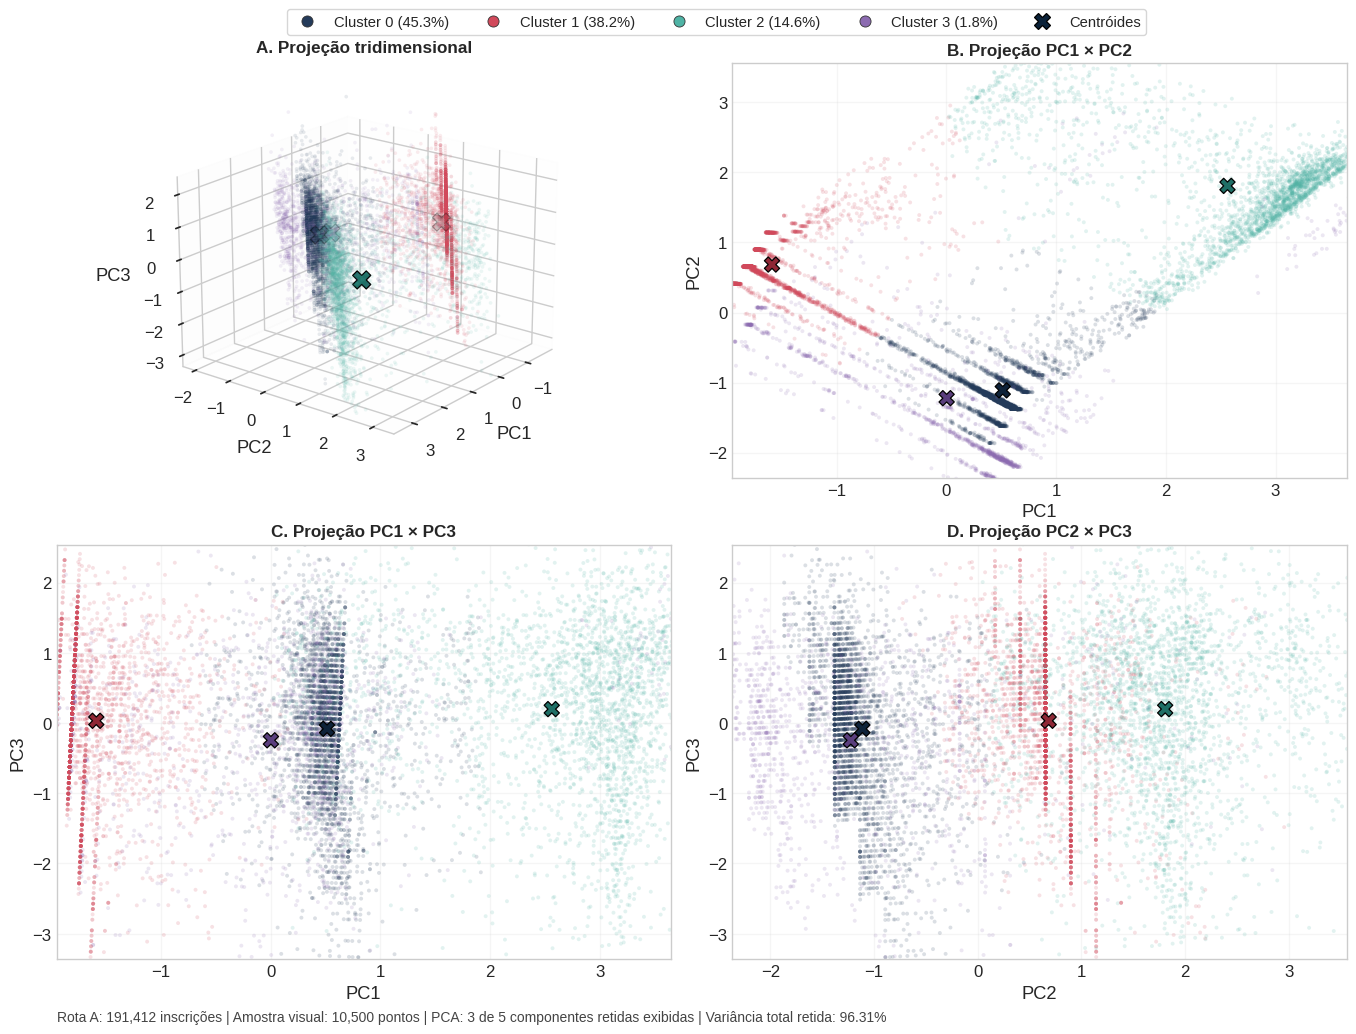


Arquivo gerado com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_a_painel_3d_2d_percentuais_legenda_refinado_300dpi.png


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# 1. CARREGAMENTO E PREPARAÇÃO DA ROTA A
print("Carregando base analítica consolidada da Rota A...")
df_rota_a = pd.read_parquet(f'{output_path}/matriz_analitica_kdd_final.parquet')

features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

faltantes = [c for c in features_ml if c not in df_rota_a.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {faltantes}")

print(f"Rota A preparada com {len(df_rota_a):,} registros.")

# 2. PADRONIZAÇÃO E PCA
print("Aplicando padronização Z-score e PCA...")
X = df_rota_a[features_ml].copy()
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.95, random_state=42)
X_pca_a = pca.fit_transform(X_scaled)

var_total = pca.explained_variance_ratio_.sum() * 100
print(f"PCA concluído: {X.shape[1]} -> {pca.n_components_} componentes | Variância retida = {var_total:.2f}%")

if X_pca_a.shape[1] < 3:
    raise ValueError("O PCA gerou menos de 3 componentes. Não é possível montar o painel 3D + 2D.")

# 3. K-MEANS DEFINITIVO (K=4)
print("Instanciando K-Means (K=4) sobre o subespaço ortogonal...")
kmeans_pca = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
clusters_k4 = kmeans_pca.fit_predict(X_pca_a)

df_rota_a = df_rota_a.copy()
df_rota_a['Cluster_K4'] = clusters_k4
df_rota_a['PC1'] = X_pca_a[:, 0]
df_rota_a['PC2'] = X_pca_a[:, 1]
df_rota_a['PC3'] = X_pca_a[:, 2]

distribuicao = df_rota_a['Cluster_K4'].value_counts().sort_index()
pct = {cluster: (count / len(df_rota_a)) * 100 for cluster, count in distribuicao.items()}

print("\n[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]")
for cluster, count in distribuicao.items():
    print(f"   -> Cluster {cluster}: {count:,} inscrições ({(count/len(df_rota_a))*100:.1f}%)")

# 4. AMOSTRAGEM ESTRATIFICADA BALANCEADA PARA VISUALIZAÇÃO
amostra_por_cluster = {
    0: 3500,
    1: 3200,
    2: 2600,
    3: 1200
}

amostras = []
for cluster_id, n_amostra in amostra_por_cluster.items():
    df_cluster = df_rota_a[df_rota_a['Cluster_K4'] == cluster_id]
    n_final = min(len(df_cluster), n_amostra)
    amostras.append(df_cluster.sample(n=n_final, random_state=42))

df_plot = pd.concat(amostras, axis=0).copy()
centroides_pca3 = kmeans_pca.cluster_centers_[:, :3]

# 5. CONFIGURAÇÃO VISUAL
plt.style.use('seaborn-v0_8-whitegrid')

cores = {
    0: '#243b5a',  # azul petróleo escuro
    1: '#d1495b',  # vermelho suave
    2: '#4fb3a5',  # verde água
    3: '#8c6bb1'   # roxo suave
}

cores_centroides = {
    0: '#0e2239',
    1: '#8f2735',
    2: '#1f6f66',
    3: '#5a3e7d'
}

labels = {
    0: f'Cluster 0 ({pct.get(0, 0):.1f}%)',
    1: f'Cluster 1 ({pct.get(1, 0):.1f}%)',
    2: f'Cluster 2 ({pct.get(2, 0):.1f}%)',
    3: f'Cluster 3 ({pct.get(3, 0):.1f}%)'
}

fig = plt.figure(figsize=(15, 11.2))
gs = fig.add_gridspec(
    2, 2,
    left=0.06, right=0.92, top=0.90, bottom=0.10,
    hspace=0.16, wspace=0.10
)

ax3d = fig.add_subplot(gs[0, 0], projection='3d')
ax12 = fig.add_subplot(gs[0, 1])
ax13 = fig.add_subplot(gs[1, 0])
ax23 = fig.add_subplot(gs[1, 1])

pc1_min, pc1_max = np.percentile(df_plot['PC1'], [0.5, 99.5])
pc2_min, pc2_max = np.percentile(df_plot['PC2'], [0.5, 99.5])
pc3_min, pc3_max = np.percentile(df_plot['PC3'], [0.5, 99.5])

# 6. PAINEL 3D
for i in [0, 1, 2, 3]:
    idx = df_plot['Cluster_K4'] == i
    ax3d.scatter(
        df_plot.loc[idx, 'PC1'],
        df_plot.loc[idx, 'PC2'],
        df_plot.loc[idx, 'PC3'],
        c=cores[i],
        s=7,
        alpha=0.10,
        edgecolors='none',
        depthshade=False
    )

ax3d.scatter(
    centroides_pca3[:, 0],
    centroides_pca3[:, 1],
    centroides_pca3[:, 2],
    c=[cores_centroides[0], cores_centroides[1], cores_centroides[2], cores_centroides[3]],
    s=170,
    marker='X',
    edgecolors='black',
    linewidth=0.9
)

ax3d.set_title('A. Projeção tridimensional', fontsize=12.3, fontweight='bold', pad=8)
ax3d.set_xlabel('PC1', labelpad=6)
ax3d.set_ylabel('PC2', labelpad=6)
ax3d.set_zlabel('PC3', labelpad=6)
ax3d.view_init(elev=20, azim=38)
ax3d.set_xlim(pc1_min, pc1_max)
ax3d.set_ylim(pc2_min, pc2_max)
ax3d.set_zlim(pc3_min, pc3_max)
ax3d.xaxis.pane.set_alpha(0.05)
ax3d.yaxis.pane.set_alpha(0.05)
ax3d.zaxis.pane.set_alpha(0.05)
ax3d.grid(True, alpha=0.15)

# 7. FUNÇÃO PARA PROJEÇÕES 2D
def plot_2d(ax, xcol, ycol, xlabel, ylabel, titulo, cx, cy, xlim=None, ylim=None):
    for i in [0, 1, 2, 3]:
        idx = df_plot['Cluster_K4'] == i
        ax.scatter(
            df_plot.loc[idx, xcol],
            df_plot.loc[idx, ycol],
            c=cores[i],
            s=8,
            alpha=0.16,
            edgecolors='none',
            rasterized=True
        )
    ax.scatter(
        centroides_pca3[:, cx],
        centroides_pca3[:, cy],
        c=[cores_centroides[0], cores_centroides[1], cores_centroides[2], cores_centroides[3]],
        s=120,
        marker='X',
        edgecolors='black',
        linewidth=0.9,
        zorder=5
    )
    ax.set_title(titulo, fontsize=12.3, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.grid(True, alpha=0.18)

plot_2d(ax12, 'PC1', 'PC2', 'PC1', 'PC2', 'B. Projeção PC1 × PC2', 0, 1, (pc1_min, pc1_max), (pc2_min, pc2_max))
plot_2d(ax13, 'PC1', 'PC3', 'PC1', 'PC3', 'C. Projeção PC1 × PC3', 0, 2, (pc1_min, pc1_max), (pc3_min, pc3_max))
plot_2d(ax23, 'PC2', 'PC3', 'PC2', 'PC3', 'D. Projeção PC2 × PC3', 1, 2, (pc2_min, pc2_max), (pc3_min, pc3_max))

# 8. LEGENDA EXTERNA MANUAL COM PERCENTUAIS
legend_elements = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=labels[i],
        markerfacecolor=cores[i],
        markeredgecolor='#333333',
        markeredgewidth=0.6,
        markersize=8,
        alpha=1.0
    )
    for i in [0, 1, 2, 3]
]

legend_elements.append(
    Line2D(
        [0], [0],
        marker='X',
        color='w',
        label='Centróides',
        markerfacecolor='#0b2239',
        markeredgecolor='black',
        markeredgewidth=0.9,
        markersize=11,
        alpha=1.0
    )
)

fig.legend(
    handles=legend_elements,
    loc='upper center',
    ncol=5,
    bbox_to_anchor=(0.50, 0.955),
    frameon=True,
    fontsize=10.6
)

# 9. RODAPÉ METODOLÓGICO
fig.text(
    0.06, 0.045,
    f"Rota A: {len(df_rota_a):,} inscrições | Amostra visual: {len(df_plot):,} pontos | PCA: 3 de {pca.n_components_} componentes retidas exibidas | Variância total retida: {var_total:.2f}%",
    fontsize=10.0,
    color="#444444"
)

# 10. EXPORTAÇÃO
output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)

arquivo_png = os.path.join(output_dir, "rota_a_painel_3d_2d_percentuais_legenda_refinado_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivo gerado com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")

## 5. Caracterização Pedagógica (Profiling): Tradução Espacial em Comportamento

[PERFILAMENTO DOS AGRUPAMENTOS: COMPORTAMENTO TÍPICO DA MACROPOLÍTICA]


,Mediana: Nota Final (0-100),Mediana: Progresso (%),Horas_Reais_Medianas,Dias_Reais_Medianos,Mediana: Tentativas,Mediana: Idade
Cluster_K4,,,,,,
0,91.0,100.0,0.0,0.0,1.0,41.0
1,0.0,0.0,0.0,0.0,1.0,41.0
2,94.0,100.0,14.4,20.0,1.0,42.0
3,78.0,87.5,0.0,0.0,4.0,41.0



GERANDO ANÁLISE VISUAL DE DISTRIBUIÇÃO ESPACIAL (K=4)
----------------------------------------------------------------------


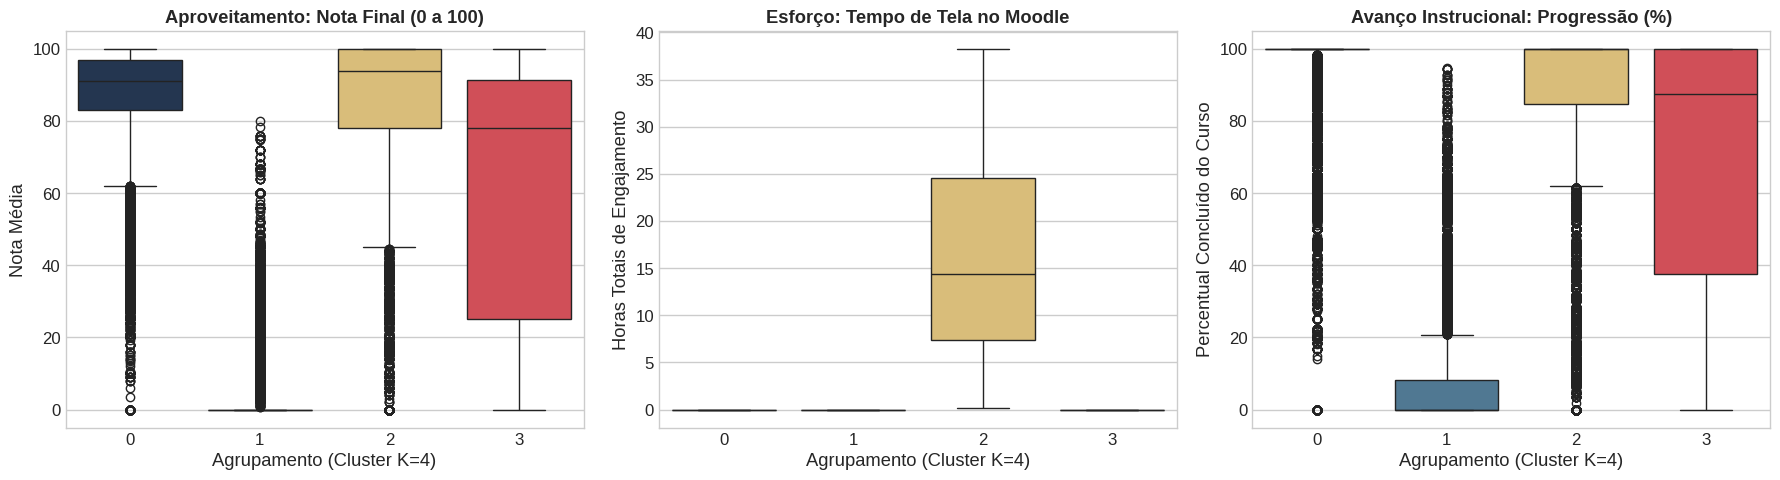

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")


# 1. Definição das variáveis do subespaço atual (sem as antigas variáveis de volumetria)
colunas_perfil_a = [
    'nota_final_kdd',
    'progresso_kdd',
    'qtd_tentativas',
    'Idade',
    'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

# Agrupamento e cálculo da Mediana (robusta contra a assimetria da evasão crônica)
df_perfil_a = df_rota_a.groupby('Cluster_K4')[colunas_perfil_a].median()

# 2. Reversão da Transformação Logarítmica (Exponencial Inversa)
df_perfil_a['Horas_Reais_Medianas'] = (np.expm1(df_perfil_a['minutos_totais_log1p']) / 60).round(1)
df_perfil_a['Dias_Reais_Medianos'] = np.expm1(df_perfil_a['dias_permanencia_log1p']).round(1)

# Limpeza e formatação do DataFrame para exibição acadêmica
df_perfil_a = df_perfil_a.drop(columns=['minutos_totais_log1p', 'dias_permanencia_log1p'])
df_perfil_a = df_perfil_a.rename(columns={
    'nota_final_kdd': 'Mediana: Nota Final (0-100)',
    'progresso_kdd': 'Mediana: Progresso (%)',
    'qtd_tentativas': 'Mediana: Tentativas',
    'Idade': 'Mediana: Idade'
})

# Reordenamento semântico das colunas
df_perfil_a = df_perfil_a[['Mediana: Nota Final (0-100)', 'Mediana: Progresso (%)',
                           'Horas_Reais_Medianas', 'Dias_Reais_Medianos',
                           'Mediana: Tentativas', 'Mediana: Idade']]

print("[PERFILAMENTO DOS AGRUPAMENTOS: COMPORTAMENTO TÍPICO DA MACROPOLÍTICA]")
display(df_perfil_a)

# 3. VISUALIZAÇÃO DISTRIBUCIONAL DA REDE: BOXPLOTS COMPARATIVOS
print("\n" + "=" * 70)
print("GERANDO ANÁLISE VISUAL DE DISTRIBUIÇÃO ESPACIAL (K=4)")
print("-" * 70)

# Criação da coluna de horas reais apenas para o escopo da plotagem
df_rota_a['horas_reais_plot'] = np.expm1(df_rota_a['minutos_totais_log1p']) / 60

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Paleta oficial da Rota A
cores_clusters_a = ['#1d3557', '#457b9d', '#e9c46a', '#e63946']

# Gráfico 1: Aproveitamento (Nota Final)
sns.boxplot(x='Cluster_K4', y='nota_final_kdd', data=df_rota_a, ax=axes[0], palette=cores_clusters_a)
axes[0].set_title('Aproveitamento: Nota Final (0 a 100)', fontweight='bold')
axes[0].set_xlabel('Agrupamento (Cluster K=4)')
axes[0].set_ylabel('Nota Média')

# Gráfico 2: Esforço Cognitivo (Tempo de Tela) - Outliers ocultados visualmente
sns.boxplot(x='Cluster_K4', y='horas_reais_plot', data=df_rota_a, ax=axes[1], palette=cores_clusters_a, showfliers=False)
axes[1].set_title('Esforço: Tempo de Tela no Moodle', fontweight='bold')
axes[1].set_xlabel('Agrupamento (Cluster K=4)')
axes[1].set_ylabel('Horas Totais de Engajamento')

# Gráfico 3: Progressão Instrucional (%)
sns.boxplot(x='Cluster_K4', y='progresso_kdd', data=df_rota_a, ax=axes[2], palette=cores_clusters_a)
axes[2].set_title('Avanço Instrucional: Progressão (%)', fontweight='bold')
axes[2].set_xlabel('Agrupamento (Cluster K=4)')
axes[2].set_ylabel('Percentual Concluído do Curso')

plt.tight_layout()
plt.show()


Carregando base analítica consolidada da Rota A...
Rota A preparada com 191,412 registros.
Aplicando padronização Z-score, PCA e K-Means...

[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]
   -> Cluster 0: 86,775 inscrições (45.3%)
   -> Cluster 1: 73,175 inscrições (38.2%)
   -> Cluster 2: 27,977 inscrições (14.6%)
   -> Cluster 3: 3,485 inscrições (1.8%)

----------------------------------------------------------------------
Iniciando Caracterização Macropolítica dos Agrupamentos (K=4)...
[RAIO-X DOS AGRUPAMENTOS: MÉTRICAS CENTRAIS DE COMPORTAMENTO]


,Mediana: Nota Final,Mediana: Progresso (%),Horas_Reais_Medianas,Dias_Reais_Medianos,Mediana: Tentativas,Mediana: Idade
Cluster_K4,,,,,,
0,91.0,100.0,0.0,0.0,1.0,41.0
1,0.0,0.0,0.0,0.0,1.0,41.0
2,94.0,100.0,14.4,20.0,1.0,42.0
3,78.0,87.5,0.0,0.0,4.0,41.0



GERANDO BOXPLOTS VERTICAIS DE PROFILING MACROPOLÍTICO (VERSÃO FINAL)
----------------------------------------------------------------------


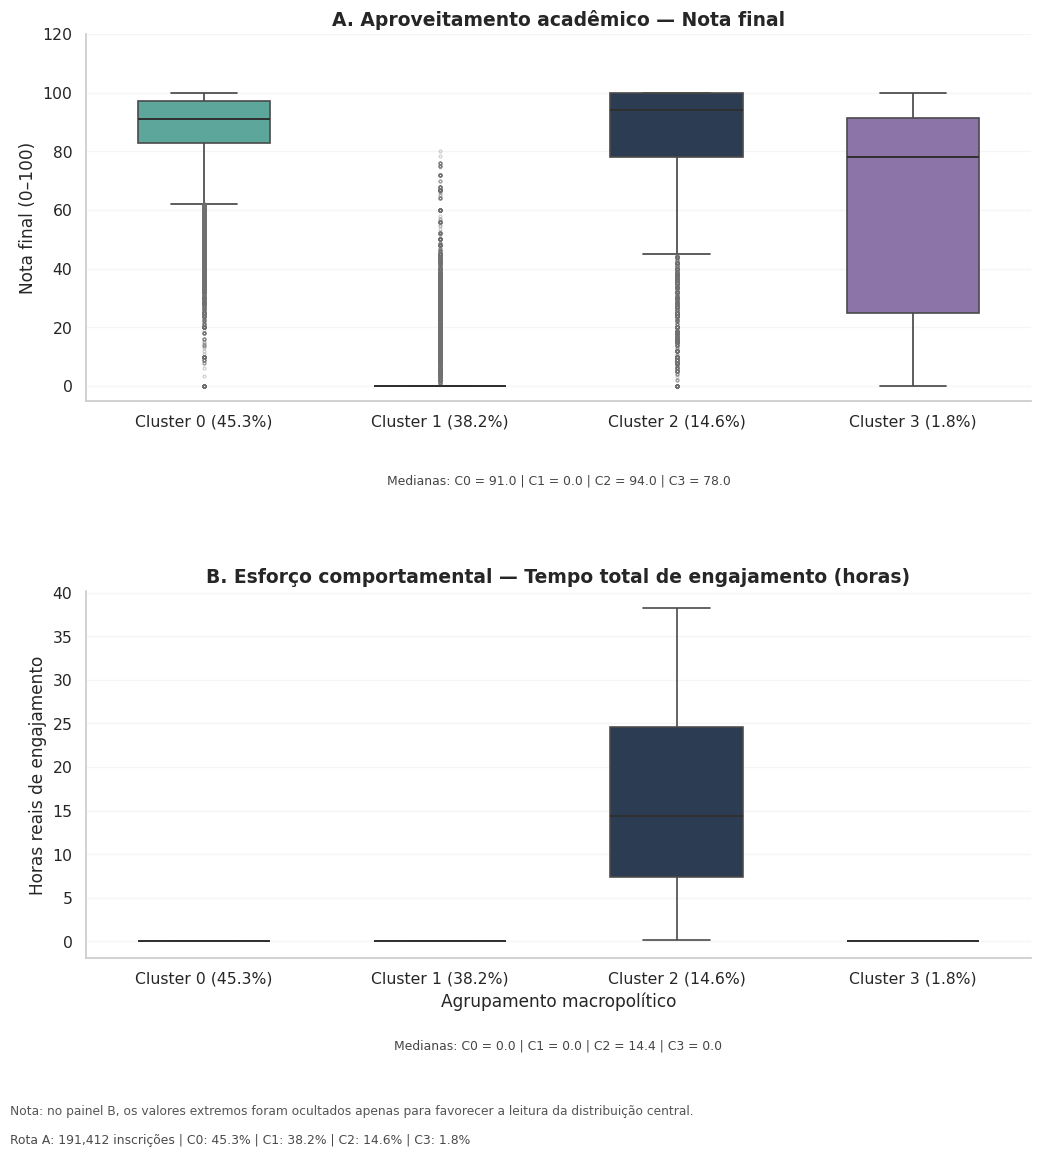


Arquivo gerado com sucesso:
 - PNG 300 dpi: /content/dados_output/figuras/rota_a_boxplots_profiling_vertical_espacamento_final_300dpi.png


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# 1. CARREGAMENTO E PREPARAÇÃO
print("Carregando base analítica consolidada da Rota A...")
df_rota_a = pd.read_parquet(f'{output_path}/matriz_analitica_kdd_final.parquet')

features_ml = [
    'Idade',
    'Escolaridade_Ordinal',
    'qtd_tentativas',
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

faltantes = [c for c in features_ml if c not in df_rota_a.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {faltantes}")

print(f"Rota A preparada com {len(df_rota_a):,} registros.")

# 2. PADRONIZAÇÃO, PCA E K-MEANS (K=4)
print("Aplicando padronização Z-score, PCA e K-Means...")
X = df_rota_a[features_ml].copy()
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=0.95, random_state=42)
X_pca_a = pca.fit_transform(X_scaled)

kmeans_pca = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
clusters_k4 = kmeans_pca.fit_predict(X_pca_a)

df_rota_a = df_rota_a.copy()
df_rota_a['Cluster_K4'] = clusters_k4

distribuicao = df_rota_a['Cluster_K4'].value_counts().sort_index()
pct = (distribuicao / len(df_rota_a) * 100).round(1)

print("\n[VOLUMETRIA DOS AGRUPAMENTOS DESCOBERTOS]")
for cluster, count in distribuicao.items():
    print(f"   -> Cluster {cluster}: {count:,} inscrições ({pct.loc[cluster]:.1f}%)")

# 3. TABELA DESCRITIVA DE APOIO
print("\n" + "-" * 70)
print("Iniciando Caracterização Macropolítica dos Agrupamentos (K=4)...")

colunas_perfil = [
    'nota_final_kdd',
    'progresso_kdd',
    'minutos_totais_log1p',
    'dias_permanencia_log1p',
    'qtd_tentativas',
    'Idade'
]

df_perfil = df_rota_a.groupby('Cluster_K4')[colunas_perfil].median()

df_perfil['Horas_Reais_Medianas'] = (np.expm1(df_perfil['minutos_totais_log1p']) / 60).round(1)
df_perfil['Dias_Reais_Medianos'] = np.expm1(df_perfil['dias_permanencia_log1p']).round(1)

df_perfil = df_perfil.drop(columns=['minutos_totais_log1p', 'dias_permanencia_log1p'])
df_perfil = df_perfil.rename(columns={
    'nota_final_kdd': 'Mediana: Nota Final',
    'progresso_kdd': 'Mediana: Progresso (%)',
    'qtd_tentativas': 'Mediana: Tentativas',
    'Idade': 'Mediana: Idade'
})

df_perfil = df_perfil[[
    'Mediana: Nota Final',
    'Mediana: Progresso (%)',
    'Horas_Reais_Medianas',
    'Dias_Reais_Medianos',
    'Mediana: Tentativas',
    'Mediana: Idade'
]]

print("[RAIO-X DOS AGRUPAMENTOS: MÉTRICAS CENTRAIS DE COMPORTAMENTO]")
try:
    display(df_perfil)
except NameError:
    print(df_perfil)

# 4. VARIÁVEIS DE PLOTAGEM
df_rota_a['Horas_Reais_Engajamento'] = np.expm1(df_rota_a['minutos_totais_log1p']) / 60

labels_clusters = {
    0: f"Cluster 0 ({pct.loc[0]:.1f}%)",
    1: f"Cluster 1 ({pct.loc[1]:.1f}%)",
    2: f"Cluster 2 ({pct.loc[2]:.1f}%)",
    3: f"Cluster 3 ({pct.loc[3]:.1f}%)"
}

df_rota_a['Perfil_Label'] = df_rota_a['Cluster_K4'].map(labels_clusters)

ordem = [
    labels_clusters[0],
    labels_clusters[1],
    labels_clusters[2],
    labels_clusters[3]
]

cores = ['#243b5a', '#d1495b', '#4fb3a5', '#8c6bb1']

# 5. FIGURA PRINCIPAL
print("\n" + "=" * 70)
print("GERANDO BOXPLOTS VERTICAIS DE PROFILING MACROPOLÍTICO (VERSÃO FINAL)")
print("-" * 70)

sns.set_theme(style="whitegrid", font_scale=1.02)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12.2, 12.0),
    gridspec_kw={'hspace': 0.52}
)

# Painel A: Nota final
sns.boxplot(
    x='Perfil_Label',
    y='nota_final_kdd',
    hue='Perfil_Label',
    data=df_rota_a,
    ax=axes[0],
    palette=cores,
    order=ordem,
    legend=False,
    width=0.56,
    linewidth=1.20,
    boxprops=dict(edgecolor='#4a4a4a', linewidth=1.20),
    whiskerprops=dict(color='#4a4a4a', linewidth=1.25),
    capprops=dict(color='#4a4a4a', linewidth=1.25),
    medianprops=dict(color='#2f2f2f', linewidth=1.4),
    flierprops=dict(
        marker='o',
        markersize=2.0,
        markerfacecolor='none',
        markeredgecolor='#707070',
        alpha=0.30
    )
)

axes[0].set_title('A. Aproveitamento acadêmico — Nota final', fontsize=13.5, fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Nota final (0–100)')
axes[0].set_ylim(-5, 120)
axes[0].set_yticks(np.arange(0, 121, 20))
axes[0].grid(True, axis='y', alpha=0.18)

# Painel B: Tempo de engajamento
sns.boxplot(
    x='Perfil_Label',
    y='Horas_Reais_Engajamento',
    hue='Perfil_Label',
    data=df_rota_a,
    ax=axes[1],
    palette=cores,
    order=ordem,
    legend=False,
    width=0.56,
    linewidth=1.15,
    boxprops=dict(edgecolor='#4a4a4a', linewidth=1.15),
    whiskerprops=dict(color='#4a4a4a', linewidth=1.20),
    capprops=dict(color='#4a4a4a', linewidth=1.20),
    medianprops=dict(color='#2f2f2f', linewidth=1.35),
    showfliers=False
)

axes[1].set_title('B. Esforço comportamental — Tempo total de engajamento (horas)', fontsize=13.5, fontweight='bold')
axes[1].set_xlabel('Agrupamento macropolítico')
axes[1].set_ylabel('Horas reais de engajamento')
axes[1].grid(True, axis='y', alpha=0.18)

# Refinos visuais
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()

# 6. TEXTOS, MEDIANAS E RODAPÉS
med_nota = []
med_tempo = []

for label in ordem:
    med_nota.append(df_rota_a.loc[df_rota_a['Perfil_Label'] == label, 'nota_final_kdd'].median())
    med_tempo.append(df_rota_a.loc[df_rota_a['Perfil_Label'] == label, 'Horas_Reais_Engajamento'].median())

texto_mediana_a = (
    f"Medianas: "
    f"C0 = {med_nota[0]:.1f} | "
    f"C1 = {med_nota[1]:.1f} | "
    f"C2 = {med_nota[2]:.1f} | "
    f"C3 = {med_nota[3]:.1f}"
)

texto_mediana_b = (
    f"Medianas: "
    f"C0 = {med_tempo[0]:.1f} | "
    f"C1 = {med_tempo[1]:.1f} | "
    f"C2 = {med_tempo[2]:.1f} | "
    f"C3 = {med_tempo[3]:.1f}"
)

axes[0].text(
    0.5, -0.20,
    texto_mediana_a,
    transform=axes[0].transAxes,
    ha='center', va='top',
    fontsize=8.9, color='#444444'
)

axes[1].text(
    0.5, -0.22,
    texto_mediana_b,
    transform=axes[1].transAxes,
    ha='center', va='top',
    fontsize=8.9, color='#444444'
)

axes[1].text(
    -0.08, -0.40,
    "Nota: no painel B, os valores extremos foram ocultados apenas para favorecer a leitura da distribuição central.",
    transform=axes[1].transAxes,
    ha='left', va='top',
    fontsize=8.8, color="#555555"
)

axes[1].text(
    -0.08, -0.48,
    f"Rota A: {len(df_rota_a):,} inscrições | C0: {pct.loc[0]:.1f}% | C1: {pct.loc[1]:.1f}% | C2: {pct.loc[2]:.1f}% | C3: {pct.loc[3]:.1f}%",
    transform=axes[1].transAxes,
    ha='left', va='top',
    fontsize=8.9, color="#4a4a4a"
)

# 7. EXPORTAÇÃO
output_dir = output_path + "/figuras"
os.makedirs(output_dir, exist_ok=True)
arquivo_png = os.path.join(output_dir, "rota_a_boxplots_profiling_vertical_espacamento_final_300dpi.png")

fig.savefig(
    arquivo_png,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

print("\nArquivo gerado com sucesso:")
print(f" - PNG 300 dpi: {arquivo_png}")

## 6. Consolidação e Exportação do Diagnóstico Macropolítico

In [ ]:
# Calcular medianas por cluster para identificação comportamental
medianas_cluster = df_rota_a.groupby('Cluster_K4')[['nota_final_kdd', 'progresso_kdd', 'qtd_tentativas']].median()

# Identificar cluster com evasão crônica: nota=0 e progresso=0
cluster_evasao = medianas_cluster[
    (medianas_cluster['nota_final_kdd'] == 0) & (medianas_cluster['progresso_kdd'] == 0)
].index.tolist()

# Identificar cluster com engajamento pleno: progresso=100 e nota alta
cluster_engajamento = medianas_cluster[
    (medianas_cluster['progresso_kdd'] == 100) & (medianas_cluster['nota_final_kdd'] >= 80)
].index.tolist()

# Identificar os clusters restantes (Certificação Expressa e Resiliência com Fricção)
ja_identificados = set(cluster_evasao + cluster_engajamento)
restantes = [c for c in medianas_cluster.index if c not in ja_identificados]

# Dentre os restantes, o de maior número de tentativas é 'Resiliência com Fricção'
if len(restantes) >= 2:
    tentativas_restantes = medianas_cluster.loc[restantes, 'qtd_tentativas']
    cluster_friccao = tentativas_restantes.idxmax()
    cluster_certificacao = [c for c in restantes if c != cluster_friccao][0]
elif len(restantes) == 1:
    cluster_friccao = restantes[0]
    cluster_certificacao = None
else:
    cluster_friccao = None
    cluster_certificacao = None

# Construção dinâmica do dicionário de personas
dicionario_personas_a = {}
for c in cluster_evasao:
    dicionario_personas_a[c] = 'Evasão Crônica (Inércia Absoluta)'
for c in cluster_engajamento:
    dicionario_personas_a[c] = 'Engajamento Orgânico (Aprendizagem Cadenciada)'
if cluster_friccao is not None:
    dicionario_personas_a[cluster_friccao] = 'Resiliência com Fricção (Retrabalho Avaliativo)'
if cluster_certificacao is not None:
    dicionario_personas_a[cluster_certificacao] = 'Certificação Expressa (Ausência de Rastro)'

print("[MAPEAMENTO COMPORTAMENTAL DE PERSONAS - IDENTIFICAÇÃO DINÂMICA]")
for cluster_id, persona in sorted(dicionario_personas_a.items()):
    mediana_nota = medianas_cluster.loc[cluster_id, 'nota_final_kdd']
    mediana_prog = medianas_cluster.loc[cluster_id, 'progresso_kdd']
    print(f"-> Cluster {cluster_id} -> {persona} (Nota mediana: {mediana_nota:.0f}, Progresso mediano: {mediana_prog:.0f}%)")

# 2. Instanciação da coluna categórica definitiva na Base Analítica
df_rota_a['Persona_Macropolitica'] = df_rota_a['Cluster_K4'].map(dicionario_personas_a)

# 3. Exportação dos dados (Formato CSV para interoperabilidade com ferramentas gerenciais)
caminho_exportacao = output_path + '/matriz_rota_a_clusterizada_final.csv'
df_rota_a.to_csv(caminho_exportacao, index=False, encoding='utf-8')

print(f"\n[SUCESSO] Base Analítica Global exportada com {len(df_rota_a):,} inscrições rotuladas.")
print(f"-> Diretório de salvamento: {caminho_exportacao}")


[MAPEAMENTO COMPORTAMENTAL DE PERSONAS - IDENTIFICAÇÃO DINÂMICA]
-> Cluster 0 -> Engajamento Orgânico (Aprendizagem Cadenciada) (Nota mediana: 91, Progresso mediano: 100%)
-> Cluster 1 -> Evasão Crônica (Inércia Absoluta) (Nota mediana: 0, Progresso mediano: 0%)
-> Cluster 2 -> Engajamento Orgânico (Aprendizagem Cadenciada) (Nota mediana: 94, Progresso mediano: 100%)
-> Cluster 3 -> Resiliência com Fricção (Retrabalho Avaliativo) (Nota mediana: 78, Progresso mediano: 88%)

[SUCESSO] Base Analítica Global exportada com 191,412 inscrições rotuladas.
-> Diretório de salvamento: /content/dados_output/matriz_rota_a_clusterizada_final.csv


## 7. Geração da tabela de "Cargas dos Componentes Principais (PCA) - Rota A (Rede Global)"

In [ ]:
import pandas as pd
from IPython.display import display

# 1. Definindo as features explicitamente para evitar erros de memória
features_ml = [
    'Idade', 'Escolaridade_Ordinal', 'qtd_tentativas',
    'nota_final_kdd', 'progresso_kdd', 'minutos_totais_log1p',
    'dias_permanencia_log1p'
]

# 2. Extraindo as cargas do objeto PCA correto da Rota A
cargas_a = pca_opt_a.components_
num_pcs_a = cargas_a.shape[0] # O notebook indica que foram retidos 5 PCs
colunas_pc_a = [f'PC{i+1}' for i in range(num_pcs_a)]

# 3. Montando o DataFrame
cargas_pca_a = pd.DataFrame(
    cargas_a.T,
    columns=colunas_pc_a,
    index=features_ml
)

print("--- CARGAS DO PCA (ROTA A) ---")
display(cargas_pca_a.round(3))

# 4. Gerando o código LaTeX blindado
latex_cargas_a = cargas_pca_a.round(3).to_latex(
    float_format="%.3f",
    column_format="l" + "r" * num_pcs_a,
    escape=True
)

# Corrigindo caracteres especiais para o compilador LaTeX
latex_cargas_a = latex_cargas_a.replace('_', r'\_').replace('&', '&')

latex_str_a = f"""\\begin{{table}}[htbp]
\\centering
\\caption{{Cargas dos Componentes Principais (PCA) - Rota A (Rede Global)}}
\\label{{tab:pca_cargas_a}}
\\resizebox{{\\textwidth}}{{!}}{{%
{latex_cargas_a.strip()}
}}
\\vspace{{0.15cm}}
{{\\raggedright \\footnotesize \\textbf{{Fonte:}} Elaborado pelos autores (2026). \\par}}
{{\\raggedright \\footnotesize \\textbf{{Nota:}} Valores indicam a correlação linear entre as variáveis originais e os componentes principais retidos. \\par}}
\\end{{table}}"""

print("\n" + "=" * 70)
print("CÓDIGO LATEX PARA O ARTIGO (ROTA A):")
print("-" * 70)
print(latex_str_a)

--- CARGAS DO PCA (ROTA A) ---


,PC1,PC2,PC3,PC4,PC5
Idade,0.023,-0.001,0.733,-0.011,-0.680
Escolaridade_Ordinal,-0.081,-0.181,0.667,0.032,0.716
qtd_tentativas,0.002,-0.111,-0.028,0.992,-0.045
nota_final_kdd,0.542,-0.447,-0.039,-0.050,-0.022
progresso_kdd,0.538,-0.455,-0.030,-0.056,-0.012
minutos_totais_log1p,0.459,0.519,0.060,0.066,0.077
dias_permanencia_log1p,0.445,0.528,0.106,0.063,0.129



CÓDIGO LATEX PARA O ARTIGO (ROTA A):
----------------------------------------------------------------------
\begin{table}[htbp]
\centering
\caption{Cargas dos Componentes Principais (PCA) - Rota A (Rede Global)}
\label{tab:pca_cargas_a}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lrrrrr}
\toprule
 & PC1 & PC2 & PC3 & PC4 & PC5 \\
\midrule
Idade & 0.023 & -0.001 & 0.733 & -0.011 & -0.680 \\
Escolaridade\\_Ordinal & -0.081 & -0.181 & 0.667 & 0.032 & 0.716 \\
qtd\\_tentativas & 0.002 & -0.111 & -0.028 & 0.992 & -0.045 \\
nota\\_final\\_kdd & 0.542 & -0.447 & -0.039 & -0.050 & -0.022 \\
progresso\\_kdd & 0.538 & -0.455 & -0.030 & -0.056 & -0.012 \\
minutos\\_totais\\_log1p & 0.459 & 0.519 & 0.060 & 0.066 & 0.077 \\
dias\\_permanencia\\_log1p & 0.445 & 0.528 & 0.106 & 0.063 & 0.129 \\
\bottomrule
\end{tabular}
}
\vspace{0.15cm}
{\raggedright \footnotesize \textbf{Fonte:} Elaborado pelos autores (2026). \par}
{\raggedright \footnotesize \textbf{Nota:} Valores indicam a correlação linear ent